# County Presidential Participation Final Data Preparation and EDA
**Author:** Mikaela Beck  
**Final capstone:** Required Capstone Project 24.1  
**Analysis date:** October 29, 2026

## Problem and scope
The original proposal asked which demographic, political, and campaign-context factors predict U.S. county turnout. The final operational question is: **How well can county demographic and prior presidential voting patterns explain variation in 2024 presidential participation across counties in different states?**

The outcome is 2024 presidential votes per 100 estimated residents age 18+. This is a voting-age-population participation proxy, not an official registered-voter or eligible-voter turnout rate. The denominator includes noncitizens and other ineligible adults and represents ACS five-year estimates for 2020–2024. The numerator excludes ballots without a presidential vote. This is retrospective supervised regression, not a pre-election forecast or an estimate of campaign effects.

This notebook rebuilds the analytical data and visualizes its quality and patterns. Run it before `02_model_selection_and_evaluation.ipynb`. The second notebook performs model comparisons, grouped nested cross-validation, hyperparameter grid search, uncertainty assessment, and interpretation.

## Changes from Module 20
The raw data snapshots are retained. The final analysis corrects Jackson County, Missouri by combining its two separately reported election-board jurisdictions in both years. The earlier draft omitted the Kansas City jurisdiction. That was a preparation error in our initial analysis; it is corrected here and recorded in `reports/jackson_county_harmonization.csv`. Official jurisdiction descriptions support the aggregation: [Kansas City Election Board](https://kceb.org/board/faq/) and [Jackson County Election Board](https://jcebmo.org/election-information/jurisdiction/).

Eight predictors are fixed before the final searches: population size, two age shares, income, education, poverty, and two prior political-context measures. Race/ethnicity shares are excluded from final modeling; the Module 20 sensitivity result motivated this choice, so final evaluation is explicitly exploratory. Prior turnout, FEC spending, urban/rural classification, and clustering remain outside this completed analysis. No unsupported variable is invented to fill those gaps.

In [1]:
from pathlib import Path
import gzip
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'data/raw').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw').exists(), 'Run from the project root or notebooks directory.'
RAW = ROOT / 'data/raw'
PROCESSED = ROOT / 'data/processed'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
SEED = 42
pd.set_option('display.max_columns', 16)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160})

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close()

sources = json.loads((RAW / 'sources.json').read_text())
display(Markdown('**Reproducibility:** raw snapshots and SHA-256 checksums are in `data/raw/sources.json`. All processing and modeling below use those local snapshots.'))

LABELS = {
    'log_population': 'County population (log10)',
    'pct_age_18_29': 'Residents age 18–29 (%)',
    'pct_age_65_plus': 'Residents age 65+ (%)',
    'median_household_income': 'Median household income (2024 dollars)',
    'pct_bachelors_plus': 'Adults 25+ with bachelor degree or higher (%)',
    'pct_poverty': 'Residents below poverty threshold (%)',
    'prior_dem_share_pct': '2020 Democratic two-party share (%)',
    'prior_competitiveness': '2020 two-party competitiveness (0–100)',
    'participation_pct': '2024 presidential participation proxy (%)',
}

**Reproducibility:** raw snapshots and SHA-256 checksums are in `data/raw/sources.json`. All processing and modeling below use those local snapshots.

## 1. Sources and geographic coverage
Election returns originate with [MIT Election Data and Science Lab, Harvard Dataverse V20](https://doi.org/10.7910/DVN/VOQCHQ). This notebook uses the [Election Data mirror](https://electiondata.dev/datasets/county-president/) because Harvard's direct file endpoint required a guestbook response. The mirror normalizes vote modes and reporting-unit identifiers. Its provenance/version are preserved; equality to a directly downloaded Harvard datafile was not independently checked.

Demographics originate with the U.S. Census Bureau's ACS and were retrieved from [Census Reporter](https://censusreporter.org/about/), release `acs2024_5yr` (2020–2024). Both estimates and margins of error are preserved in the raw JSON. Tables: B01001 age, B15003 education, B17001 poverty, B19013 household income, and B03002 race/ethnicity. This descriptive analysis uses point estimates; ACS sampling uncertainty is not propagated into the model.

The join uses five-digit county FIPS, never county names. Alaska election districts do not align with borough/census-area geography. Connecticut's old election counties do not align with the new ACS planning regions. Unmatched units remain in an audit file and are excluded from modeling without invented crosswalks. Puerto Rico has ACS data but no general-election presidential county votes in these returns.

Kansas City's separately reported jurisdiction is harmonized to Jackson County as described above. Alaska election districts remain excluded; no speculative crosswalk is applied.

In [2]:
election_2024 = pd.read_csv(RAW / 'elections_2024.csv', dtype={'county_fips': 'string'})
election_2020 = pd.read_csv(RAW / 'elections_2020.csv', dtype={'county_fips': 'string'})
with gzip.open(RAW / 'acs2024_counties.json.gz', 'rt') as handle:
    acs_payload = json.load(handle)
assert acs_payload['release']['id'] == 'acs2024_5yr'
assert set(election_2024['year']) == {2024}
assert set(election_2020['year']) == {2020}
audit = {'raw_election_2024_rows': len(election_2024), 'raw_election_2020_rows': len(election_2020), 'acs_counties': len(acs_payload['data'])}
display(pd.DataFrame([
    {'source': '2024 candidate rows', 'rows': len(election_2024)},
    {'source': '2020 candidate rows', 'rows': len(election_2020)},
    {'source': 'ACS county records', 'rows': len(acs_payload['data'])},
]))
display(pd.DataFrame({table: {'title': metadata['title'], 'universe': metadata['universe']} for table, metadata in acs_payload['tables'].items()}).T)

,source,rows
0,2024 candidate rows,12514
1,2020 candidate rows,13656
2,ACS county records,3222


,title,universe
B01001,Sex by Age,Total population
B03002,Hispanic or Latino Origin by Race,Total population
B15003,Educational Attainment for the Population 25 Y...,Population 25 years and over
B17001,Poverty Status in the Past 12 Months by Sex by...,Population for whom poverty status is determined
B19013,Median Household Income in the Past 12 Months ...,Households


## 2. Election cleaning: prevent repeated-total double counting
Each candidate row repeats a county's `totalvotes`. Summing that field would multiply turnout by the number of candidates. First confirm one unique total per reporting unit, then retain it once. Exact duplicate rows are counted and removed; conflicting candidate keys cause an assertion failure. The sum of candidate votes is a separate reconciliation check. Differences are flagged and retained because the source explicitly supplies the county total; they are not silently overwritten. Sensitivity to flagged counties is assessed later.

In [3]:
def summarize_election(frame, label):
    audit[label + '_exact_duplicate_rows'] = int(frame.duplicated().sum())
    frame = frame.drop_duplicates().copy()
    candidate_keys = ['year', 'state_po', 'unit_id', 'candidate', 'party']
    assert not frame.duplicated(candidate_keys).any(), 'Conflicting candidate keys require inspection.'
    assert frame.groupby('unit_id')['totalvotes'].nunique().max() == 1
    grouped = frame.groupby('unit_id', dropna=False)
    units = grouped.agg(county_fips=('county_fips', 'first'), county_name=('county_name', 'first'), state=('state_po', 'first'), total_votes=('totalvotes', 'first'))
    units['candidate_vote_sum'] = grouped['candidatevotes'].sum(min_count=1)
    units['candidate_total_gap'] = units['candidate_vote_sum'] - units['total_votes']
    units['candidate_gap_pct'] = 100 * units['candidate_total_gap'] / units['total_votes']
    units['total_reconciliation_flag'] = units['candidate_total_gap'].ne(0)
    valid_fips = units['county_fips'].str.fullmatch(r'\d{5}', na=False)
    audit[label + '_reporting_units'] = len(units)
    audit[label + '_units_without_county_fips'] = int((~valid_fips).sum())
    unassigned = units.loc[~valid_fips].copy()
    unassigned['resolution'] = np.where(unassigned['state'].eq('MO') & unassigned['county_name'].eq('KANSAS CITY'), 'Recovered in Jackson County total', 'Excluded: noncounty reporting geography')
    unassigned.to_csv(REPORTS / (label + '_noncounty_units.csv'))
    units.loc[units['total_reconciliation_flag']].to_csv(REPORTS / (label + '_vote_reconciliation.csv'))
    units = units.loc[valid_fips].reset_index()
    assert not units['county_fips'].duplicated().any()
    audit[label + '_valid_county_units'] = len(units)
    audit[label + '_reconciliation_flags'] = int(units['total_reconciliation_flag'].sum())
    return units

counties_2024 = summarize_election(election_2024, 'election_2024')
counties_2020 = summarize_election(election_2020, 'election_2020')
harmonization_rows = []
for election_year, candidate_frame, county_frame in [(2020, election_2020, counties_2020), (2024, election_2024, counties_2024)]:
    kansas_city = candidate_frame.loc[candidate_frame['state_po'].eq('MO') & candidate_frame['county_name'].eq('KANSAS CITY')]
    assert kansas_city['unit_id'].nunique() == 1
    assert kansas_city['totalvotes'].nunique() == 1
    jackson_mask = county_frame['county_fips'].eq('29095')
    assert int(jackson_mask.sum()) == 1
    county_votes_before = int(county_frame.loc[jackson_mask, 'total_votes'].iloc[0])
    additional_votes = int(kansas_city['totalvotes'].iloc[0])
    county_frame.loc[jackson_mask, 'total_votes'] += additional_votes
    county_frame.loc[jackson_mask, 'candidate_vote_sum'] += kansas_city['candidatevotes'].sum(min_count=1)
    county_frame.loc[jackson_mask, 'candidate_total_gap'] = county_frame.loc[jackson_mask, 'candidate_vote_sum'] - county_frame.loc[jackson_mask, 'total_votes']
    county_frame.loc[jackson_mask, 'candidate_gap_pct'] = 100 * county_frame.loc[jackson_mask, 'candidate_total_gap'] / county_frame.loc[jackson_mask, 'total_votes']
    county_frame.loc[jackson_mask, 'total_reconciliation_flag'] = county_frame.loc[jackson_mask, 'candidate_total_gap'].ne(0)
    audit[f'election_{election_year}_kansas_city_votes_recovered'] = additional_votes
    harmonization_rows.append({'year': election_year, 'county_fips': '29095', 'county_total_before': county_votes_before, 'separate_kansas_city_votes': additional_votes, 'corrected_county_total': county_votes_before + additional_votes})
pd.DataFrame(harmonization_rows).to_csv(REPORTS / 'jackson_county_harmonization.csv', index=False)
mapped_2020 = election_2020.copy()
mapped_2020.loc[mapped_2020['state_po'].eq('MO') & mapped_2020['county_name'].eq('KANSAS CITY'), 'county_fips'] = '29095'
prior_party_votes = mapped_2020.dropna(subset=['county_fips']).groupby(['county_fips', 'party'])['candidatevotes'].sum(min_count=1).unstack()
two_party_votes = prior_party_votes['DEMOCRAT'] + prior_party_votes['REPUBLICAN']
prior_context = pd.DataFrame({
    'prior_dem_share_pct': 100 * prior_party_votes['DEMOCRAT'] / two_party_votes,
    'prior_competitiveness': 100 * (1 - (prior_party_votes['DEMOCRAT'] - prior_party_votes['REPUBLICAN']).abs() / two_party_votes),
}).reset_index()
display(pd.Series(audit, name='count').to_frame())
display(counties_2024.loc[counties_2024['total_reconciliation_flag'], ['state', 'county_name', 'candidate_vote_sum', 'total_votes', 'candidate_gap_pct']].sort_values('candidate_gap_pct').head(8))
display(pd.DataFrame(harmonization_rows))

,count
raw_election_2024_rows,12514
raw_election_2020_rows,13656
acs_counties,3222
election_2024_exact_duplicate_rows,0
election_2024_reporting_units,3154
election_2024_units_without_county_fips,42
election_2024_valid_county_units,3112
election_2024_reconciliation_flags,127
election_2020_exact_duplicate_rows,0
election_2020_reporting_units,3155


,state,county_name,candidate_vote_sum,total_votes,candidate_gap_pct
67,AZ,APACHE,32101.0,32685,-1.786752
795,IA,GREENE,4881.0,4968,-1.751208
778,IA,CLARKE,4479.0,4552,-1.603691
79,AZ,SANTA CRUZ,19167.0,19428,-1.343422
831,IA,PAGE,7322.0,7419,-1.307454
809,IA,JEFFERSON,8346.0,8454,-1.277502
761,IA,ALLAMAKEE,7318.0,7410,-1.241565
851,IA,WAYNE,3124.0,3162,-1.201771


,year,county_fips,county_total_before,separate_kansas_city_votes,corrected_county_total
0,2020,29095,196418,136645,333063
1,2024,29095,193729,124288,318017


## 3. Feature engineering and target validity
Adult population equals total population minus all male/female under-18 age bins in B01001. Age shares use total population; bachelor-or-higher attainment uses the population age 25+; poverty uses the population for whom poverty status is determined. Income is in 2024 inflation-adjusted dollars. The log10 of population represents county size.

The 2020 Democratic share is the Democratic vote divided by Democratic plus Republican votes, multiplied by 100. Prior competitiveness is `100 × (1 − |D − R|/(D + R))`: 100 means a tied two-party contest, 0 means one party received all two-party votes. Both use the corrected Jackson/Kansas City aggregation.

Negative Census sentinel values become missing. Missing predictor values will be imputed within each modeling fold. County names, state, and FIPS are not model predictors. State is reserved for grouping validation folds. Rows with missing/nonpositive adult denominators or proxy values outside 0–100 are excluded and logged; valid IQR outliers are retained. These choices acknowledge measurement incompatibility, not evidence of improper voting. Race/ethnicity fields may remain in preserved source/audit data but are not final model inputs.

In [4]:
acs_rows = []
for geoid, tables in acs_payload['data'].items():
    record = {'county_fips': geoid[-5:], 'acs_county_name': acs_payload['geography'][geoid]['name']}
    for table_id, table_data in tables.items():
        for variable, estimate in table_data['estimate'].items():
            record[variable] = estimate
    acs_rows.append(record)
acs = pd.DataFrame(acs_rows)
assert not acs['county_fips'].duplicated().any()
numeric_columns = [column for column in acs if column.startswith('B')]
acs[numeric_columns] = acs[numeric_columns].apply(pd.to_numeric, errors='coerce')
audit['acs_negative_sentinel_cells'] = int((acs[numeric_columns] < 0).sum().sum())
acs[numeric_columns] = acs[numeric_columns].mask(acs[numeric_columns] < 0)

def age_sum(frame, bins):
    return frame[[f'B01001{number:03d}' for number in bins]].sum(axis=1, min_count=len(bins))

acs['population'] = acs['B01001001']
acs['adult_population'] = acs['population'] - age_sum(acs, [3, 4, 5, 6, 27, 28, 29, 30])
acs['pct_age_18_29'] = 100 * age_sum(acs, list(range(7, 12)) + list(range(31, 36))) / acs['population']
acs['pct_age_65_plus'] = 100 * age_sum(acs, list(range(20, 26)) + list(range(44, 50))) / acs['population']
acs['pct_bachelors_plus'] = 100 * acs[[f'B15003{number:03d}' for number in range(22, 26)]].sum(axis=1, min_count=4) / acs['B15003001']
acs['pct_poverty'] = 100 * acs['B17001002'] / acs['B17001001']
acs['median_household_income'] = acs['B19013001']
acs['pct_nonhispanic_white'] = 100 * acs['B03002003'] / acs['B03002001']
acs['pct_nonhispanic_black'] = 100 * acs['B03002004'] / acs['B03002001']
acs['pct_hispanic'] = 100 * acs['B03002012'] / acs['B03002001']
acs['log_population'] = np.log10(acs['population'].where(acs['population'] > 0))

demographic_columns = ['population', 'adult_population', 'pct_age_18_29', 'pct_age_65_plus', 'pct_bachelors_plus', 'pct_poverty', 'median_household_income', 'pct_nonhispanic_white', 'pct_nonhispanic_black', 'pct_hispanic', 'log_population']
merged = counties_2024.merge(acs[['county_fips', 'acs_county_name'] + demographic_columns], on='county_fips', how='left', validate='one_to_one', indicator=True)
unmatched = merged.loc[merged['_merge'] != 'both', ['county_fips', 'county_name', 'state']].copy()
unmatched.to_csv(REPORTS / 'election_counties_without_acs.csv', index=False)
audit['county_units_unmatched_to_acs'] = len(unmatched)
audit['acs_counties_without_2024_election_match'] = int((~acs['county_fips'].isin(counties_2024['county_fips'])).sum())
merged = merged.drop(columns='_merge').merge(prior_context, on='county_fips', how='left', validate='one_to_one')
merged['participation_pct'] = 100 * merged['total_votes'] / merged['adult_population']
merged['exclusion_reason'] = ''
merged.loc[merged['adult_population'].isna(), 'exclusion_reason'] = 'No ACS county match or missing adult population'
merged.loc[merged['adult_population'].le(0), 'exclusion_reason'] = 'Nonpositive adult population'
merged.loc[merged['participation_pct'].notna() & ~merged['participation_pct'].between(0, 100), 'exclusion_reason'] = 'Participation proxy outside 0-100'
excluded = merged.loc[merged['exclusion_reason'].ne('')].copy()
excluded.to_csv(REPORTS / 'excluded_counties.csv', index=False)
analysis = merged.loc[merged['exclusion_reason'].eq('')].drop(columns='exclusion_reason').copy()
analysis.replace([np.inf, -np.inf], np.nan, inplace=True)
FEATURES = ['log_population', 'pct_age_18_29', 'pct_age_65_plus', 'median_household_income', 'pct_bachelors_plus', 'pct_poverty', 'pct_nonhispanic_white', 'pct_nonhispanic_black', 'pct_hispanic', 'prior_dem_share_pct', 'prior_competitiveness']
FEATURES = ['log_population', 'pct_age_18_29', 'pct_age_65_plus', 'median_household_income', 'pct_bachelors_plus', 'pct_poverty', 'prior_dem_share_pct', 'prior_competitiveness']
assert analysis['county_fips'].is_unique
assert analysis['participation_pct'].between(0, 100).all()
assert analysis[FEATURES].notna().any().all()
for feature in [column for column in FEATURES if column.startswith('pct_') or column.startswith('prior_')]:
    assert analysis[feature].dropna().between(0, 100).all(), feature
analysis.to_csv(PROCESSED / 'county_analysis.csv', index=False)
audit.update({'excluded_county_rows': len(excluded), 'analysis_counties': len(analysis), 'analysis_states_and_dc': analysis['state'].nunique(), 'analysis_presidential_votes': int(analysis['total_votes'].sum())})
missingness = analysis[FEATURES].isna().sum().rename('missing_count').to_frame()
missingness['missing_pct'] = 100 * missingness['missing_count'] / len(analysis)
missingness.to_csv(REPORTS / 'predictor_missingness.csv')
display(pd.Series(audit, name='count').to_frame())
display(excluded[['state', 'county_name', 'participation_pct', 'exclusion_reason']])
display(Markdown('Five matched counties have ratios above 100%: Mineral (CO), Edwards, Kenedy, Loving, and McMullen (TX). They are excluded from the bounded-outcome analysis and retained in the audit. A ratio above 100% can reflect incompatibility or uncertainty in the population estimate and vote numerator; it is not evidence of improper voting. Excluding these observations also limits conclusions about small counties.'))
display(missingness.T)

/var/folders/tl/x6vvbs2d37x0tzpnb11s7l1r0000gn/T/ipykernel_27738/2526888444.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  acs['population'] = acs['B01001001']
/var/folders/tl/x6vvbs2d37x0tzpnb11s7l1r0000gn/T/ipykernel_27738/2526888444.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  acs['adult_population'] = acs['population'] - age_sum(acs, [3, 4, 5, 6, 27, 28, 29, 30])
/var/folders/tl/x6vvbs2d37x0tzpnb11s7l1r0000gn/T/ipykernel_27738/2526888444.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usuall

,count
raw_election_2024_rows,12514
raw_election_2020_rows,13656
acs_counties,3222
election_2024_exact_duplicate_rows,0
election_2024_reporting_units,3154
election_2024_units_without_county_fips,42
election_2024_valid_county_units,3112
election_2024_reconciliation_flags,127
election_2020_exact_duplicate_rows,0
election_2020_reporting_units,3155


,state,county_name,participation_pct,exclusion_reason
255,CO,MINERAL,117.107309,Participation proxy outside 0-100
279,CT,FAIRFIELD,NaN,No ACS county match or missing adult population
280,CT,HARTFORD,NaN,No ACS county match or missing adult population
281,CT,LITCHFIELD,NaN,No ACS county match or missing adult population
282,CT,MIDDLESEX,NaN,No ACS county match or missing adult population
283,CT,NEW HAVEN,NaN,No ACS county match or missing adult population
284,CT,NEW LONDON,NaN,No ACS county match or missing adult population
285,CT,TOLLAND,NaN,No ACS county match or missing adult population
286,CT,WINDHAM,NaN,No ACS county match or missing adult population
2561,TX,EDWARDS,101.106640,Participation proxy outside 0-100


Five matched counties have ratios above 100%: Mineral (CO), Edwards, Kenedy, Loving, and McMullen (TX). They are excluded from the bounded-outcome analysis and retained in the audit. A ratio above 100% can reflect incompatibility or uncertainty in the population estimate and vote numerator; it is not evidence of improper voting. Excluding these observations also limits conclusions about small counties.

,log_population,pct_age_18_29,pct_age_65_plus,median_household_income,pct_bachelors_plus,pct_poverty,prior_dem_share_pct,prior_competitiveness
missing_count,0.0,0.0,0.0,1.000000,0.0,0.0,0.0,0.0
missing_pct,0.0,0.0,0.0,0.032268,0.0,0.0,0.0,0.0


## 4. EDA: distribution, missingness, outliers, and relationships
The unit of analysis is one county/county equivalent, so county averages are unweighted. The aggregate ratio of total votes to total adult population is reported separately; neither is an official national turnout statistic. An IQR rule describes unusual values without asserting errors or removing valid counties. Population size and ACS sampling uncertainty make very small counties especially important to inspect.

,county participation (%)
count,3099.00
mean,62.50
std,9.96
min,22.36
25%,56.10
50%,62.78
75%,69.64
max,97.32


**County mean:** 62.50%; **median:** 62.78%; **aggregate ratio within the analytical sample:** 59.36%. The IQR rule flags 29 counties, retained for analysis.

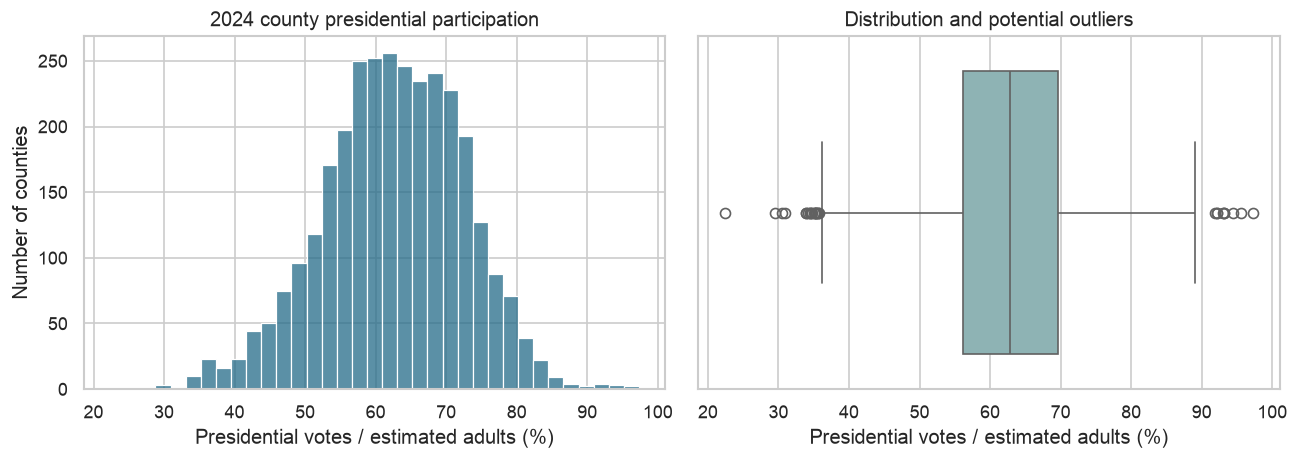

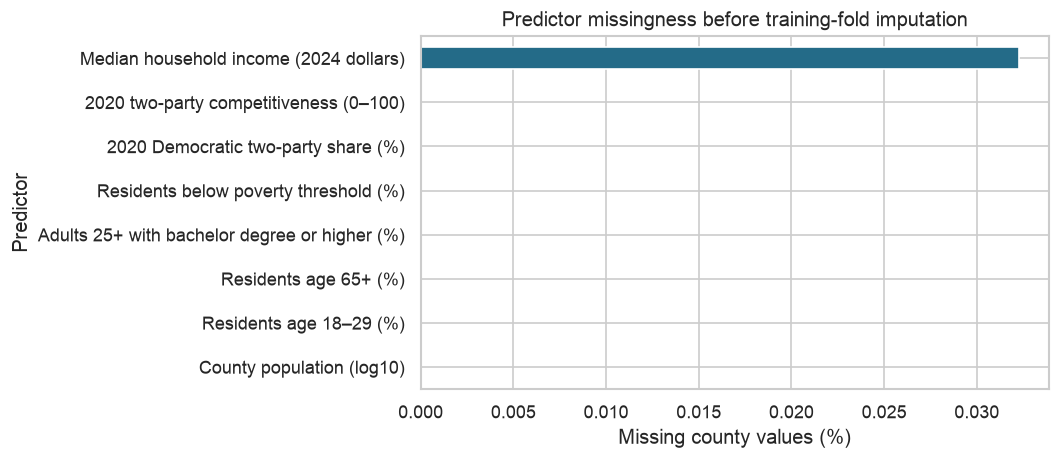

In [5]:
target = analysis['participation_pct']
first_quartile, third_quartile = target.quantile([0.25, 0.75])
iqr = third_quartile - first_quartile
analysis['target_iqr_outlier'] = ~target.between(first_quartile - 1.5 * iqr, third_quartile + 1.5 * iqr)
analysis.loc[analysis['target_iqr_outlier'], ['county_fips', 'state', 'county_name', 'total_votes', 'adult_population', 'participation_pct']].to_csv(REPORTS / 'target_iqr_outliers.csv', index=False)
distribution = target.describe().to_dict()
weighted_participation = 100 * analysis['total_votes'].sum() / analysis['adult_population'].sum()
display(target.describe().rename('county participation (%)').to_frame().round(2))
display(Markdown(f"**County mean:** {target.mean():.2f}%; **median:** {target.median():.2f}%; **aggregate ratio within the analytical sample:** {weighted_participation:.2f}%. The IQR rule flags {int(analysis['target_iqr_outlier'].sum())} counties, retained for analysis."))
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(target, bins=35, ax=axes[0], color='#246b88')
axes[0].set(title='2024 county presidential participation', xlabel='Presidential votes / estimated adults (%)', ylabel='Number of counties')
sns.boxplot(x=target, ax=axes[1], color='#87b9bb')
axes[1].set(title='Distribution and potential outliers', xlabel='Presidential votes / estimated adults (%)')
save_figure('01_participation_distribution.png')
figure, axis = plt.subplots(figsize=(9, 4))
missingness['missing_pct'].rename(index=LABELS).sort_values().plot.barh(ax=axis, color='#246b88')
axis.set(title='Predictor missingness before training-fold imputation', xlabel='Missing county values (%)', ylabel='Predictor')
save_figure('02_missingness.png')

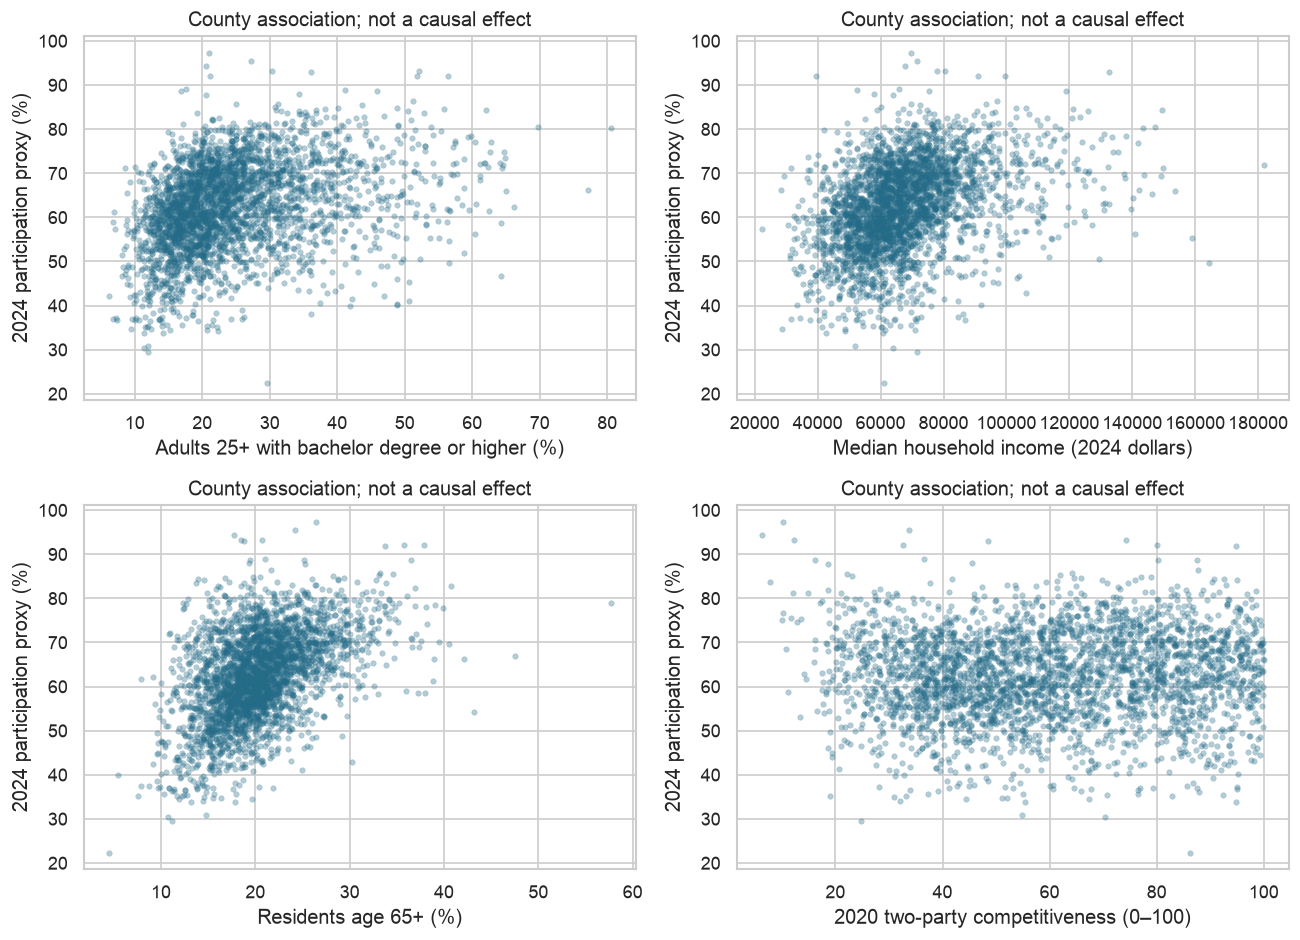

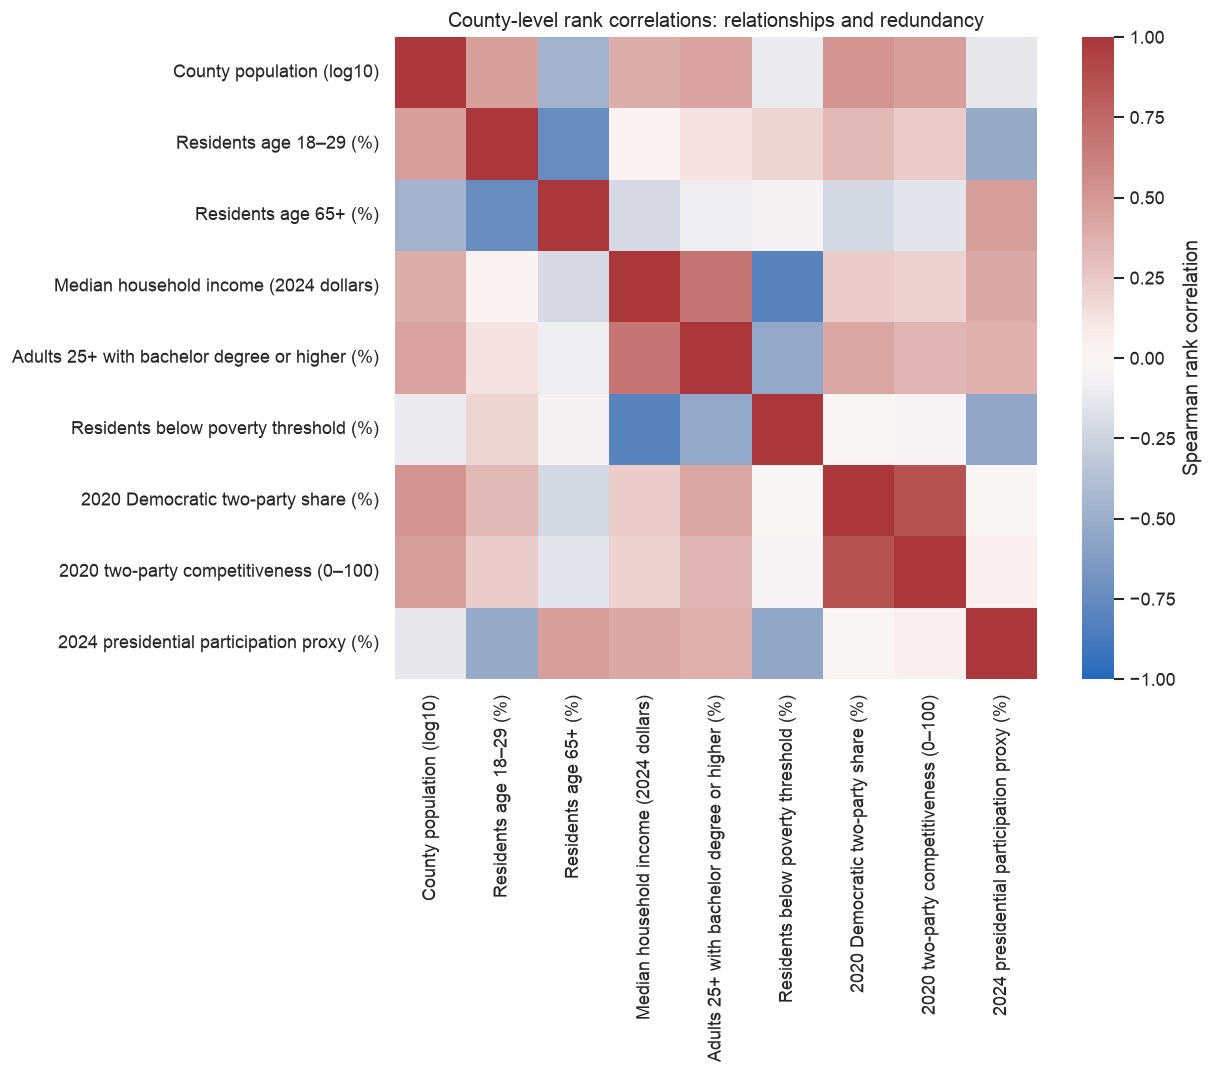

,Spearman correlation with participation
pct_poverty,-0.542
pct_age_18_29,-0.523
pct_age_65_plus,0.465
median_household_income,0.413
pct_bachelors_plus,0.371
log_population,-0.131
prior_competitiveness,0.049
prior_dem_share_pct,-0.009


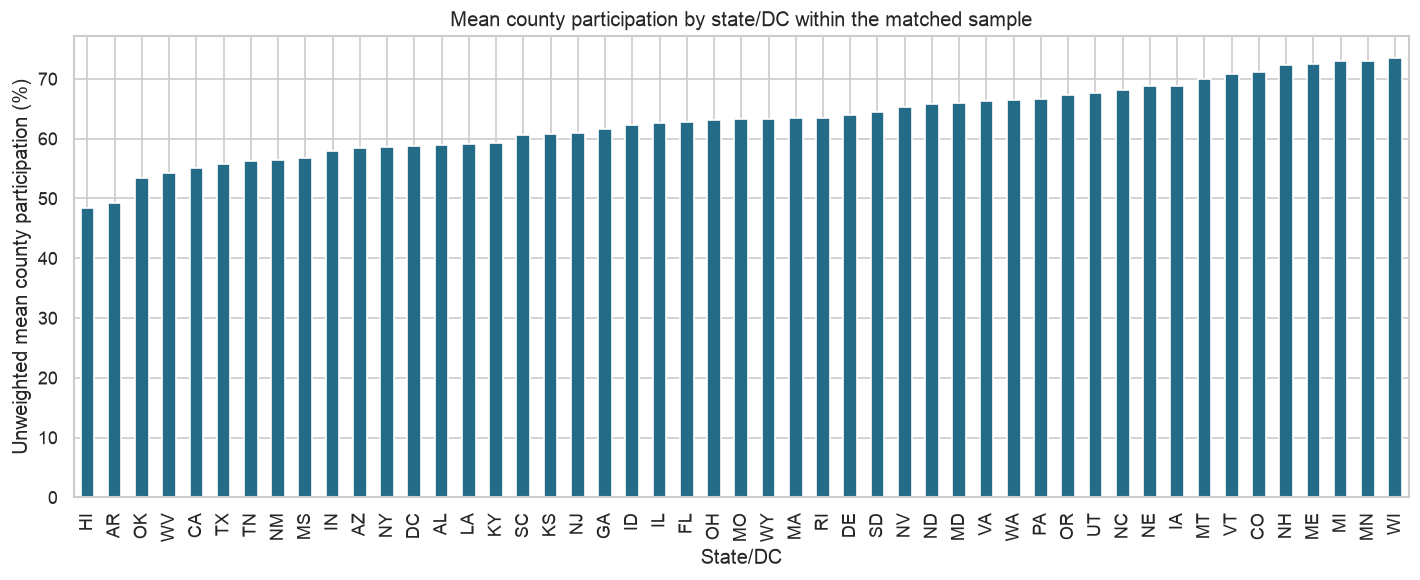

In [6]:
scatter_features = ['pct_bachelors_plus', 'median_household_income', 'pct_age_65_plus', 'prior_competitiveness']
scatter_labels = ['Adults 25+ with bachelor degree or higher (%)', 'Median household income (2024 dollars)', 'Residents age 65+ (%)', '2020 two-party competitiveness (0–100)']
figure, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, feature, label in zip(axes.flat, scatter_features, scatter_labels):
    sns.scatterplot(data=analysis, x=feature, y='participation_pct', ax=axis, s=11, alpha=0.35, color='#246b88', edgecolor=None)
    axis.set(xlabel=label, ylabel='2024 participation proxy (%)', title='County association; not a causal effect')
save_figure('03_feature_relationships.png')
correlations = analysis[FEATURES + ['participation_pct']].corr(method='spearman')
correlations.to_csv(REPORTS / 'spearman_correlations.csv')
figure, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(correlations.rename(index=LABELS, columns=LABELS), cmap='vlag', center=0, vmin=-1, vmax=1, ax=axis, square=True, cbar_kws={'label': 'Spearman rank correlation'})
axis.set(title='County-level rank correlations: relationships and redundancy')
save_figure('04_correlations.png')
target_correlations = correlations['participation_pct'].drop('participation_pct').sort_values(key=lambda values: values.abs(), ascending=False)
display(target_correlations.rename('Spearman correlation with participation').to_frame().round(3))
state_summary = analysis.groupby('state').agg(counties=('county_fips', 'size'), mean_county_participation=('participation_pct', 'mean'), votes=('total_votes', 'sum'), adults=('adult_population', 'sum'))
state_summary['aggregate_participation'] = 100 * state_summary['votes'] / state_summary['adults']
state_summary.to_csv(REPORTS / 'state_summary.csv')
figure, axis = plt.subplots(figsize=(12, 5))
state_summary['mean_county_participation'].sort_values().plot.bar(ax=axis, color='#246b88')
axis.set(title='Mean county participation by state/DC within the matched sample', xlabel='State/DC', ylabel='Unweighted mean county participation (%)')
save_figure('05_state_patterns.png')

## 5. Prepared data handoff
All derived data remain at county level. The following audit summarizes coverage, measurement exclusions, missingness, and the Missouri correction. Associations shown above are descriptive; no causal effect, individual behavior, or forecast is inferred. The final modeling notebook uses exactly the eight declared predictors and groups every validation split by state.

In [7]:
analysis.to_csv(PROCESSED / 'county_analysis.csv', index=False)
eda_summary = {
    'audit': audit,
    'distribution': {key: float(value) for key, value in target.describe().to_dict().items()},
    'aggregate_participation_pct': float(weighted_participation),
    'target_iqr_outliers': int(analysis['target_iqr_outlier'].sum()),
    'missing_predictor_cells': int(analysis[FEATURES].isna().sum().sum()),
    'features': FEATURES,
    'feature_labels': LABELS,
    'top_correlations': [{'feature': feature, 'label': LABELS[feature], 'spearman': float(value)} for feature, value in target_correlations.head(4).items()],
    'jackson_county': analysis.loc[analysis['county_fips'].eq('29095'), ['total_votes', 'adult_population', 'participation_pct']].iloc[0].to_dict(),
    'harmonization': harmonization_rows,
}
(REPORTS / 'eda_summary.json').write_text(json.dumps(eda_summary, indent=2) + '\n')
(REPORTS / 'cleaning_audit.json').write_text(json.dumps(audit, indent=2) + '\n')
dictionary_rows = [
    ('county_fips', 'Five-digit Census county identifier', 'identifier', 'Election source and Census geography'),
    ('state', 'State or DC abbreviation', 'validation group', 'Election source'),
    ('total_votes', 'Presidential votes in 2024', 'votes', 'One total per jurisdiction; Kansas City plus Jackson combined'),
    ('adult_population', 'ACS estimated residents age 18+', 'residents', 'B01001 total minus male/female under-18 bins'),
    ('participation_pct', '2024 presidential participation proxy', 'percentage points', '100 times presidential votes / estimated adult population'),
]
for feature in FEATURES:
    dictionary_rows.append((feature, LABELS[feature], 'log10 residents' if feature == 'log_population' else '2024 dollars' if feature == 'median_household_income' else 'percent or 0–100 index', 'Exact formula in this notebook; Census table definitions preserved in raw JSON'))
pd.DataFrame(dictionary_rows, columns=['variable', 'meaning', 'units', 'source_or_formula']).to_csv(PROCESSED / 'data_dictionary.csv', index=False)
assert analysis['county_fips'].is_unique
assert len(analysis) == audit['analysis_counties']
assert int(analysis.loc[analysis['county_fips'].eq('29095'), 'total_votes'].iloc[0]) == 318017
display(Markdown(f"**Prepared dataset:** {len(analysis):,} counties in {analysis['state'].nunique()} state/DC groups, {len(FEATURES)} declared model predictors. Corrected Jackson County has 318,017 presidential votes and a {eda_summary['jackson_county']['participation_pct']:.2f}% participation proxy. Proceed to Notebook 02 for all model selection and evaluation."))

**Prepared dataset:** 3,099 counties in 49 state/DC groups, 8 declared model predictors. Corrected Jackson County has 318,017 presidential votes and a 57.59% participation proxy. Proceed to Notebook 02 for all model selection and evaluation.